# Projet de Machine Learning 

### Sujet 1

**Contexte** :  Ce projet vise à mettre en place un système de maintenance prédictive pour les machines de l'usine et à analyser les causes qui font que la condition de la valve d'un cycle de production est non optimale parfois. 

**Objectif** : Construisez un modèle ML pour prédire si la condition valve est optimale (=100%) ou non, pour chaque cycle. Vous utiliserez les 2000 premiers cycles pour construire le modèle et le reste comme échantillon de test final.   

**Données** : Les données sont disponibles dans un Drive. Les données sont décrites à utiliser uniquement les 3 fichiers suivants, chaque ligne représentant un cycle :  
- PS2 (Pression (bar) échantillonnage 100Hz)  
- FS1 (Volume flow (l/min) échantillonnage 10Hz)  
- Profile : Fichier avec les variables dont la "valve condition" qui nous intéresse. 

## 1. Prétraitement des données

#### 1.1. Chargement des données et statistiques descriptives. 

In [ ]:
# Chargement des données et statistiques descriptives
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

N_DEV = 2000          # 2000 premiers cycles : construction du modèle
RANDOM_STATE = 0

# Une ligne = un cycle. Fichiers sans en-tête, colonnes séparées par des tabulations.
ps2 = pd.read_csv('data/PS2.txt', sep=r'\s+', header=None)
fs1 = pd.read_csv('data/FS1.txt', sep=r'\s+', header=None)
profile = pd.read_csv('data/profile.txt', sep=r'\s+', header=None, names=['Cooler', 'Valve', 'Pump_leakage', 'Accumulator', 'Stable_flag'])

print('PS2     :', ps2.shape, '(cycles x mesures à 100 Hz)')
print('FS1     :', fs1.shape, '(cycles x mesures à 10 Hz)')
print('profile :', profile.shape)

assert len(ps2) == len(fs1) == len(profile), 'Nombre de cycles incohérent entre les fichiers'

PS2     : (2205, 6000) (cycles x mesures à 100 Hz)
FS1     : (2205, 600) (cycles x mesures à 10 Hz)
profile : (2205, 5)


In [2]:
# Séparation : 2000 premiers cycles (développement) / cycles restants (test final)
# Le test final ne sera PAS utilisé avant l'évaluation finale.
ps2_dev, ps2_test = ps2.iloc[:N_DEV], ps2.iloc[N_DEV:]
fs1_dev, fs1_test = fs1.iloc[:N_DEV], fs1.iloc[N_DEV:]
profile_dev, profile_test = profile.iloc[:N_DEV], profile.iloc[N_DEV:]

print('Cycles de développement :', len(profile_dev))
print('Cycles de test final    :', len(profile_test))

Cycles de développement : 2000
Cycles de test final    : 205


In [3]:
# 1.1 (suite) Statistiques descriptives (sur les 2000 cycles de développement)
print('--- profile.txt (conditions des composants) ---')
print(profile_dev.describe().round(2))

print('\n--- Signaux bruts (toutes les mesures des cycles de développement) ---')
for nom, df in [('PS2 (bar)', ps2_dev), ('FS1 (l/min)', fs1_dev)]:
    v = df.to_numpy().ravel()
    print(f'{nom:12s} min={v.min():8.2f} | moyenne={v.mean():8.2f} | médiane={np.median(v):8.2f} | '
          f'max={v.max():8.2f} | écart-type={v.std():7.2f}')

--- profile.txt (conditions des composants) ---
        Cooler    Valve  Pump_leakage  Accumulator  Stable_flag
count  2000.00  2000.00       2000.00      2000.00      2000.00
mean     35.22    90.95          0.67       108.65         0.37
std      39.88    10.67          0.82        16.53         0.48
min       3.00    73.00          0.00        90.00         0.00
25%       3.00    80.00          0.00        90.00         0.00
50%      20.00   100.00          0.00       100.00         0.00
75%     100.00   100.00          1.00       130.00         1.00
max     100.00   100.00          2.00       130.00         1.00

--- Signaux bruts (toutes les mesures des cycles de développement) ---
PS2 (bar)    min=    0.00 | moyenne=  109.39 | médiane=  125.66 | max=  167.74 | écart-type=  48.18
FS1 (l/min)  min=    0.00 | moyenne=    6.16 | médiane=    7.64 | max=   20.48 | écart-type=   3.23


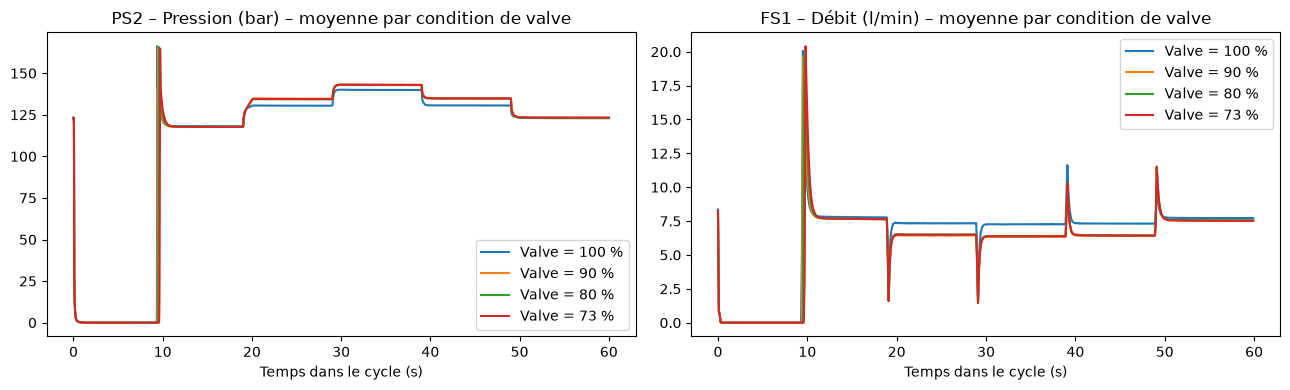

In [4]:
# Allure moyenne d'un cycle selon la condition de la valve
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, (nom, df, hz) in zip(axes, [('PS2 – Pression (bar)', ps2_dev, 100), ('FS1 – Débit (l/min)', fs1_dev, 10)]):
    t = np.arange(df.shape[1]) / hz
    for val in sorted(profile_dev['Valve'].unique(), reverse=True):
        masque = (profile_dev['Valve'] == val).to_numpy()
        ax.plot(t, df[masque].mean(axis=0), label=f'Valve = {val} %')
    ax.set_title(nom + ' – moyenne par condition de valve')
    ax.set_xlabel('Temps dans le cycle (s)')
    ax.legend()
plt.tight_layout()
plt.show()

#### 1.2. Gestion des valeurs manquantes et détection des valeurs aberrantes.

In [5]:
# Valeurs manquantes : comptage (contrôle d'intégrité sur l'ensemble des fichiers)
n_ps2, n_fs1, n_prof = int(ps2.isnull().sum().sum()), int(fs1.isnull().sum().sum()), int(profile.isnull().sum().sum())
print('Valeurs manquantes PS2     :', n_ps2)
print('Valeurs manquantes FS1     :', n_fs1)
print('Valeurs manquantes profile :', n_prof)

Valeurs manquantes PS2     : 0
Valeurs manquantes FS1     : 0
Valeurs manquantes profile : 0


In [6]:
# Gestion : interpolation le long du cycle (ligne par ligne, donc sans fuite entre cycles) uniquement si nécessaire
if n_ps2 or n_fs1:
    ps2 = ps2.interpolate(axis=1, limit_direction='both')
    fs1 = fs1.interpolate(axis=1, limit_direction='both')
    ps2_dev, ps2_test = ps2.iloc[:N_DEV], ps2.iloc[N_DEV:]
    fs1_dev, fs1_test = fs1.iloc[:N_DEV], fs1.iloc[N_DEV:]
    print('-> Valeurs manquantes interpolées le long de chaque cycle.')
else:
    print('-> Aucune valeur manquante dans les signaux : aucune imputation nécessaire.')
assert n_prof == 0, 'profile.txt contient des valeurs manquantes : à traiter avant de continuer'

-> Aucune valeur manquante dans les signaux : aucune imputation nécessaire.


In [7]:
# Résumé de chaque cycle par des statistiques (tableau de variables)
def extraire_features(df, prefixe, n_segments=6):
    X = df.to_numpy(dtype=float)
    f = pd.DataFrame(index=df.index)
    f[f'{prefixe}_mean'] = X.mean(axis=1)
    f[f'{prefixe}_std'] = X.std(axis=1)
    f[f'{prefixe}_min'] = X.min(axis=1)
    f[f'{prefixe}_max'] = X.max(axis=1)
    f[f'{prefixe}_median'] = np.median(X, axis=1)
    f[f'{prefixe}_range'] = f[f'{prefixe}_max'] - f[f'{prefixe}_min']
    f[f'{prefixe}_q25'] = np.percentile(X, 25, axis=1)
    f[f'{prefixe}_q75'] = np.percentile(X, 75, axis=1)
    f[f'{prefixe}_iqr'] = f[f'{prefixe}_q75'] - f[f'{prefixe}_q25']
    f[f'{prefixe}_skew'] = stats.skew(X, axis=1)
    f[f'{prefixe}_kurtosis'] = stats.kurtosis(X, axis=1)
    f[f'{prefixe}_rms'] = np.sqrt((X ** 2).mean(axis=1))
    t = np.arange(X.shape[1]) - (X.shape[1] - 1) / 2          # pente de la tendance linéaire
    f[f'{prefixe}_slope'] = (X - X.mean(axis=1, keepdims=True)) @ t / (t ** 2).sum()
    for i, seg in enumerate(np.array_split(X, n_segments, axis=1)):   # moyenne par tranche de temps
        f[f'{prefixe}_seg{i + 1}_mean'] = seg.mean(axis=1)
    return f

features = pd.concat([extraire_features(ps2, 'PS2'), extraire_features(fs1, 'FS1')], axis=1)
X_dev, X_test = features.iloc[:N_DEV], features.iloc[N_DEV:]

# Variables restées manquantes (ex. asymétrie d'un signal constant) : médiane du développement
if features.isnull().any().any():
    medianes = X_dev.median()
    X_dev, X_test = X_dev.fillna(medianes), X_test.fillna(medianes)

print('Tableau de variables :', features.shape, '| valeurs manquantes restantes :', int(X_dev.isnull().sum().sum() + X_test.isnull().sum().sum()))
X_dev.describe().T.round(3).head(12)

Tableau de variables : (2205, 38) | valeurs manquantes restantes : 0


,count,mean,std,min,25%,50%,75%,max
PS2_mean,2000.0,109.393,5.235,104.406,106.835,107.558,109.380,131.589
PS2_std,2000.0,47.775,3.432,45.203,46.153,46.639,47.158,59.548
PS2_min,2000.0,0.000,0.000,0.000,0.000,0.000,0.000,0.000
PS2_max,2000.0,166.450,0.998,155.040,166.100,166.570,167.020,167.740
PS2_median,2000.0,128.554,3.619,124.445,127.025,127.810,129.875,165.400
PS2_range,2000.0,166.450,0.998,155.040,166.100,166.570,167.020,167.740
PS2_q25,2000.0,117.997,1.715,112.840,116.480,117.930,120.060,120.690
PS2_q75,2000.0,132.728,12.020,125.040,127.645,128.300,130.470,165.560
PS2_iqr,2000.0,14.731,12.807,9.123,9.960,10.040,10.130,51.800
PS2_skew,2000.0,-1.771,0.146,-1.842,-1.835,-1.830,-1.794,-1.318


In [8]:
# Détection des valeurs aberrantes : règle de l'IQR, bornes calculées sur le développement
Q1, Q3 = X_dev.quantile(0.25), X_dev.quantile(0.75)
IQR = Q3 - Q1
aberrant = (X_dev < Q1 - 1.5 * IQR) | (X_dev > Q3 + 1.5 * IQR)

taux = (aberrant.mean() * 100).sort_values(ascending=False)
print('Variables avec le plus de valeurs aberrantes (% des cycles) :')
print(taux.head(8).round(1))
print(f"\nCycles ayant au moins une variable aberrante : {aberrant.any(axis=1).mean() * 100:.1f} %")
print('\nPart de cycles avec >= 1 valeur aberrante, selon la condition de la valve (%) :')
print((aberrant.any(axis=1).groupby(profile_dev['Valve']).mean() * 100).round(1))

Variables avec le plus de valeurs aberrantes (% des cycles) :
PS2_iqr          16.0
FS1_seg1_mean    15.4
FS1_std          13.2
FS1_iqr          12.6
PS2_mean         12.0
PS2_std          12.0
FS1_seg4_mean    12.0
FS1_seg5_mean    12.0
dtype: float64

Cycles ayant au moins une variable aberrante : 34.2 %

Part de cycles avec >= 1 valeur aberrante, selon la condition de la valve (%) :
Valve
73     96.6
80     28.6
90     31.0
100    18.0
dtype: float64


In [9]:
# 1.2 (suite) Vérification A : quelles variables sont aberrantes, selon la condition de la valve ?
print('--- Taux de cycles aberrants (%) par variable, selon la condition de la valve ---')
par_valve = (aberrant.groupby(profile_dev['Valve']).mean() * 100).round(1).T
print(par_valve.sort_values(73, ascending=False).head(10))

--- Taux de cycles aberrants (%) par variable, selon la condition de la valve ---
Valve           73    80    90   100
FS1_seg1_mean  96.2   0.0   0.0  0.0
PS2_iqr        23.8  23.3  23.5  9.2
FS1_std        19.1  17.9  19.7  8.0
FS1_iqr        18.8  18.6  19.7  6.9
PS2_mean       18.1  17.9  18.7  6.4
PS2_std        18.1  17.9  18.7  6.4
FS1_seg5_mean  18.1  17.9  18.7  6.4
FS1_seg4_mean  18.1  17.9  18.7  6.4
FS1_rms        18.1  17.9  18.7  6.4
FS1_q25        18.1  17.9  18.7  6.4


In [10]:
# 1.2 (suite) Vérification B : lien avec les autres colonnes de profile (pour ANALYSER uniquement, jamais comme variables)
print('--- Cycles aberrants (%) selon l\'état des autres composants ---')
for col in ['Cooler', 'Pump_leakage', 'Accumulator']:
    print(f'\nSelon {col} :')
    print((aberrant.any(axis=1).groupby(profile_dev[col]).mean() * 100).round(1).to_string())

print('\n--- Même mesure, SANS la variable FS1_seg1_mean ---')
sans = aberrant.drop(columns=['FS1_seg1_mean']).any(axis=1)
print((sans.groupby(profile_dev['Valve']).mean() * 100).round(1).to_string())
print(f'Cycles aberrants (hors FS1_seg1_mean) : {sans.mean() * 100:.1f} %')

--- Cycles aberrants (%) selon l'état des autres composants ---

Selon Cooler :
Cooler
3      55.2
20     15.8
100    30.8

Selon Pump_leakage :
Pump_leakage
0    18.6
1    51.0
2    57.2

Selon Accumulator :
Accumulator
90     27.8
100    52.4
115    40.6
130    27.0

--- Même mesure, SANS la variable FS1_seg1_mean ---
Valve
73     28.4
80     28.6
90     31.0
100    18.0
Cycles aberrants (hors FS1_seg1_mean) : 23.4 %


In [11]:
# 1.2 (suite) Vérification C : quelles variables sont aberrantes selon l'état du Cooler (analyse uniquement)
print((aberrant.groupby(profile_dev['Cooler']).mean() * 100).round(1).T.sort_values(100, ascending=False).head(8))

Cooler          3     20    100
FS1_seg1_mean  15.7  15.6  14.7
FS1_max         1.1   0.0  11.4
FS1_range       1.1   0.0  11.4
PS2_iqr        38.9   0.0   6.5
PS2_mean       32.8   0.0   0.0
PS2_std        32.8   0.0   0.0
PS2_range       6.0   0.0   0.0
PS2_median      1.9   0.0   0.0


#### 1.3. Encodage correct des variables catégorielles (si présentes). 

In [12]:
# Encodage des variables catégorielles : y en a-t-il ?
print('Types des variables explicatives :')
print(X_dev.dtypes.value_counts())
print('\nValeurs possibles de la condition de la valve :', sorted(int(v) for v in profile_dev['Valve'].unique()))

Types des variables explicatives :
float64    38
Name: count, dtype: int64

Valeurs possibles de la condition de la valve : [73, 80, 90, 100]


#### 1.4. Transformation du problème en classification binaire.

In [13]:
# Cible binaire : 1 = valve optimale (100 %), 0 = non optimale (90, 80 ou 73 %)
y_all = (profile['Valve'] == 100).astype(int)
y_dev, y_test = y_all.iloc[:N_DEV], y_all.iloc[N_DEV:]

print(pd.crosstab(profile_dev['Valve'], y_dev, rownames=['Valve (%)'], colnames=['Cible binaire']))

Cible binaire    0     1
Valve (%)               
73             320     0
80             318     0
90             310     0
100              0  1052


#### 1.5. Analyse de la distribution des classes pour vérifier l’équilibre du jeu de données.

                  Effectif  Proportion
0 – non optimale       948       0.474
1 – optimale          1052       0.526


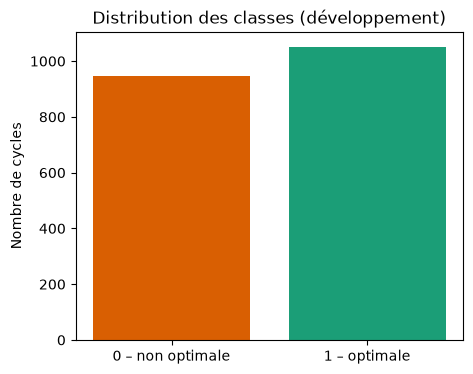

In [14]:
# Équilibre des classes (développement)
comptes = y_dev.value_counts().sort_index()
parts = y_dev.value_counts(normalize=True).sort_index()
print(pd.DataFrame({'Effectif': comptes.values, 'Proportion': parts.round(3).values},
                   index=['0 – non optimale', '1 – optimale']))

plt.figure(figsize=(5, 4))
plt.bar(['0 – non optimale', '1 – optimale'], comptes.values, color=['#d95f02', '#1b9e77'])
plt.ylabel('Nombre de cycles')
plt.title('Distribution des classes (développement)')
plt.show()

In [15]:
# Contrôle de représentativité du test final (diagnostic sur profile.txt uniquement)
# Les colonnes Cooler / Pump_leakage / Accumulator servent ici à comparer les jeux, jamais comme variables explicatives.
print(f'Part de valves optimales : développement = {y_dev.mean():.3f} | test final = {y_test.mean():.3f}')
for col in ['Cooler', 'Pump_leakage', 'Accumulator']:
    comp = pd.DataFrame({'Développement': profile_dev[col].value_counts(normalize=True),
                         'Test final': profile_test[col].value_counts(normalize=True)}).fillna(0).round(2)
    print(f'\n{col} :')
    print(comp.sort_index())

Part de valves optimales : développement = 0.526 | test final = 0.356

Cooler :
        Développement  Test final
Cooler                           
3                0.37         0.0
20               0.37         0.0
100              0.27         1.0

Pump_leakage :
              Développement  Test final
Pump_leakage                           
0                      0.56        0.49
1                      0.21        0.31
2                      0.23        0.20

Accumulator :
             Développement  Test final
Accumulator                           
90                    0.33        0.69
100                   0.17        0.31
115                   0.20        0.00
130                   0.30        0.00


#### 1.6. Analyse des corrélations entre les variables. 

In [16]:
# Corrélations entre variables et avec la cible
corr = X_dev.corr()
corr_cible = X_dev.apply(lambda col: col.corr(y_dev)).sort_values(key=abs, ascending=False)

print('Les 10 variables les plus corrélées à la cible (valve optimale) :')
print(corr_cible.head(10).round(3))

paires = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack().dropna()
fortes = paires[paires.abs() > 0.95].sort_values(key=abs, ascending=False)
print(f'\nPaires de variables fortement corrélées (|r| > 0.95) : {len(fortes)} sur {len(paires)}')
print(fortes.head(10).round(3))

Les 10 variables les plus corrélées à la cible (valve optimale) :
PS2_seg1_mean    0.800
FS1_seg1_mean    0.590
PS2_kurtosis     0.343
PS2_skew        -0.270
FS1_skew        -0.259
PS2_slope       -0.254
FS1_rms          0.239
FS1_mean         0.231
PS2_std         -0.225
FS1_seg5_mean    0.211
dtype: float64

Paires de variables fortement corrélées (|r| > 0.95) : 158 sur 666
PS2_max        PS2_range        1.000
FS1_max        FS1_range        1.000
FS1_q25        FS1_seg4_mean    1.000
PS2_q75        PS2_seg5_mean    1.000
PS2_mean       PS2_rms          0.999
PS2_seg4_mean  PS2_seg5_mean    0.999
PS2_q75        PS2_seg4_mean    0.999
FS1_seg4_mean  FS1_seg5_mean    0.999
FS1_q25        FS1_seg5_mean    0.999
FS1_mean       FS1_rms          0.998
dtype: float64


--- PS2_seg1_mean par condition de valve ---
        count  mean   std   min   25%   50%   75%   max
Valve                                                  
73      320.0  5.79  0.23  4.84  5.62  5.81  5.97  6.17
80      318.0  7.36  0.24  6.54  7.16  7.41  7.56  7.77
90      310.0  8.61  0.25  7.71  8.38  8.67  8.82  9.08
100    1052.0  9.44  0.19  8.81  9.29  9.43  9.59  9.90

--- PS2_seg1_mean par (valve optimale, Stable_flag) ---
                   count  mean   std   min   25%   50%   75%   max
Valve Stable_flag                                                 
0     0            948.0  7.24  1.18  4.84  5.96  7.40  8.37  9.08
1     0            310.0  9.45  0.25  8.81  9.21  9.48  9.66  9.90
      1            742.0  9.44  0.16  9.06  9.31  9.41  9.57  9.84

Corrélation avec Stable_flag : 0.582 | avec la cible : 0.800


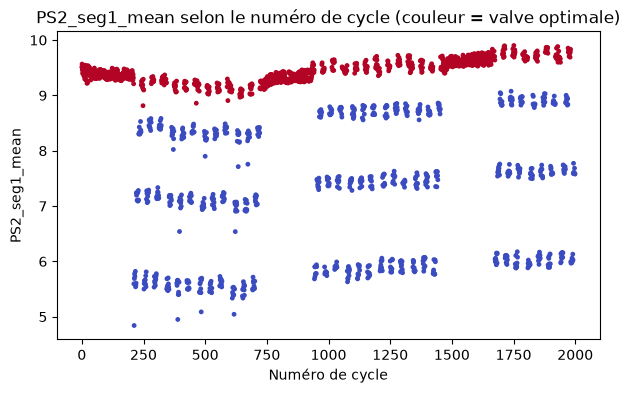

In [17]:
# 1.6 (suite) Diagnostic : pourquoi PS2_seg1_mean est-elle si corrélée à la cible ? (analyse uniquement)
v = 'PS2_seg1_mean'
print('--- %s par condition de valve ---' % v)
print(X_dev[v].groupby(profile_dev['Valve']).describe().round(2))

print('\n--- %s par (valve optimale, Stable_flag) ---' % v)
print(X_dev[v].groupby([y_dev, profile_dev['Stable_flag']]).describe().round(2))

print('\nCorrélation avec Stable_flag : %.3f | avec la cible : %.3f' % (X_dev[v].corr(profile_dev['Stable_flag']), X_dev[v].corr(y_dev)))

plt.figure(figsize=(7, 4))
plt.scatter(np.arange(N_DEV), X_dev[v], c=y_dev, cmap='coolwarm', s=6)
plt.xlabel('Numéro de cycle')
plt.ylabel(v)
plt.title(v + ' selon le numéro de cycle (couleur = valve optimale)')
plt.show()

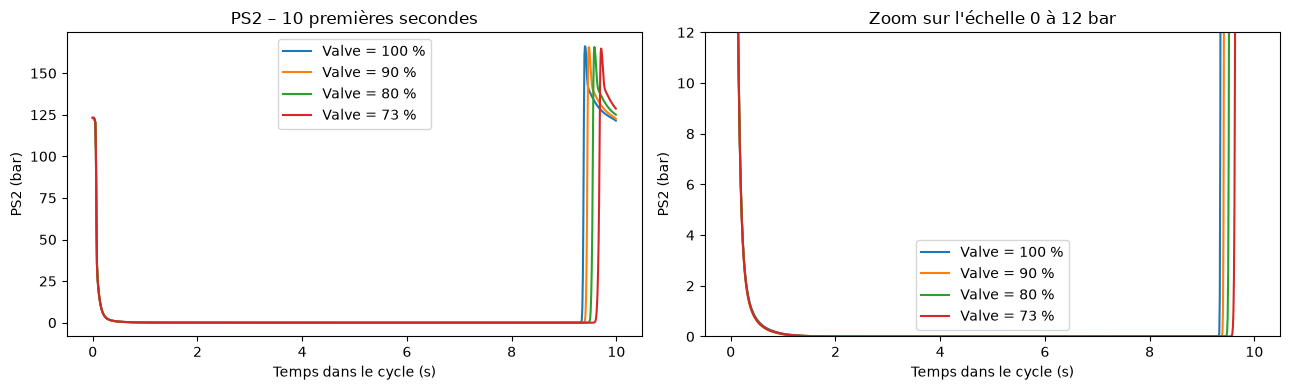

In [18]:
# 1.6 (suite) Zoom sur les 10 premières secondes de PS2, selon la condition de la valve
n10 = 10 * 100                      # 10 s à 100 Hz
t = np.arange(n10) / 100
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax in axes:
    for val in sorted(profile_dev['Valve'].unique(), reverse=True):
        masque = (profile_dev['Valve'] == val).to_numpy()
        ax.plot(t, ps2_dev.iloc[:, :n10][masque].mean(axis=0), label=f'Valve = {val} %')
    ax.set_xlabel('Temps dans le cycle (s)')
    ax.set_ylabel('PS2 (bar)')
    ax.legend()
axes[0].set_title('PS2 – 10 premières secondes')
axes[1].set_title("Zoom sur l'échelle 0 à 12 bar")
axes[1].set_ylim(0, 12)
plt.tight_layout()
plt.show()

#### 1.7. Visualisations (matrice de corrélation, histogrammes, boxplots). 

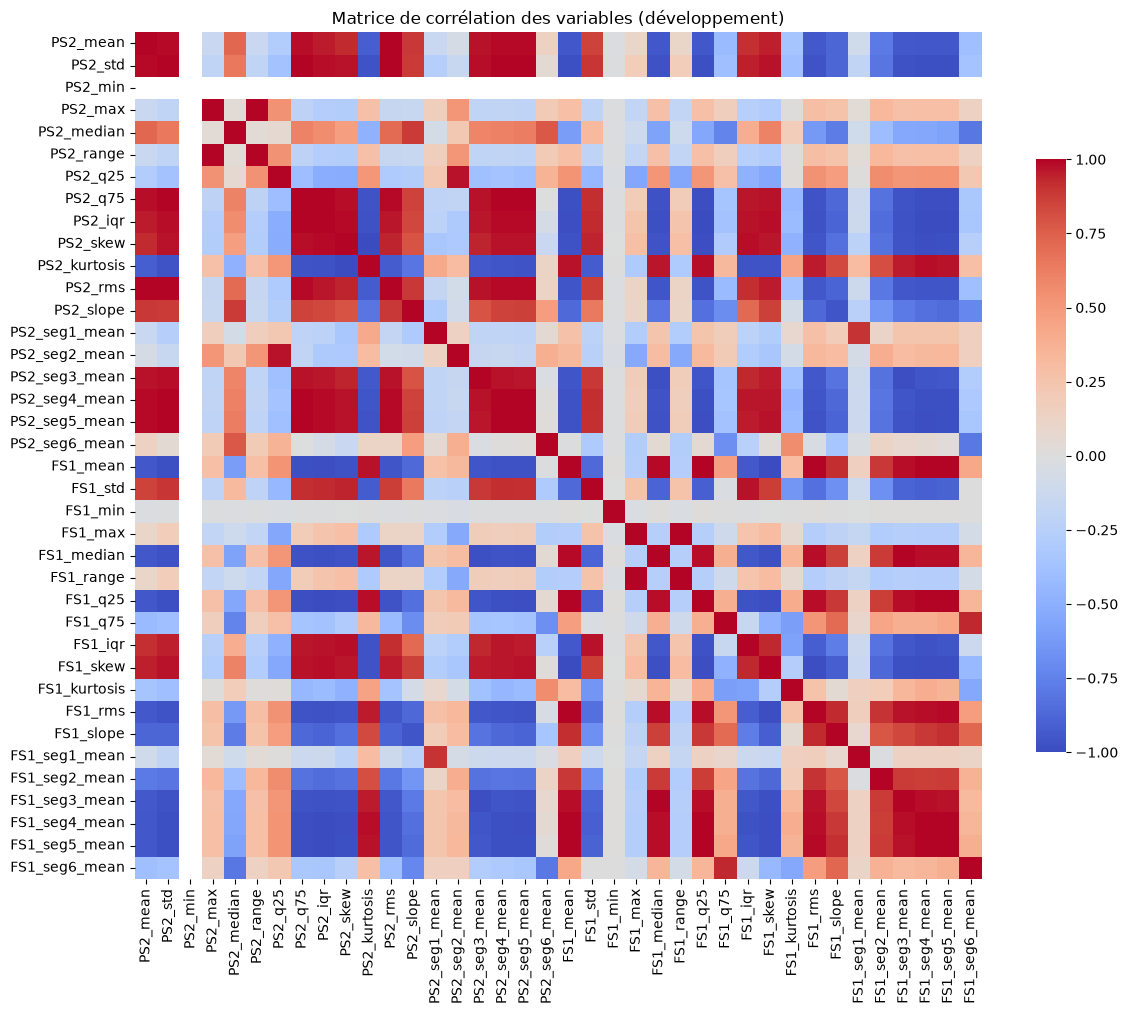

In [19]:
# Matrice de corrélation
plt.figure(figsize=(14, 11))
sns.heatmap(corr, cmap='coolwarm', center=0, vmin=-1, vmax=1, square=True, cbar_kws={'shrink': 0.7})
plt.title('Matrice de corrélation des variables (développement)')
plt.show()

In [20]:
# 1.7 (suite) Vérification : la corrélation PS2 / FS1 dépend-elle des cycles à Cooler = 3 % ? (analyse uniquement)
m = profile_dev['Cooler'] != 3
print('r(PS2_mean, FS1_mean), tous les cycles       : %.3f' % X_dev['PS2_mean'].corr(X_dev['FS1_mean']))
print('r(PS2_mean, FS1_mean), sans Cooler = 3 %%      : %.3f' % X_dev.loc[m, 'PS2_mean'].corr(X_dev.loc[m, 'FS1_mean']))

r(PS2_mean, FS1_mean), tous les cycles       : -0.953
r(PS2_mean, FS1_mean), sans Cooler = 3 %      : 0.386


In [21]:
# 1.7 (suite) Les redondances entre variables dépendent-elles des cycles à Cooler = 3 % ? (analyse uniquement)
def paires_fortes(X, seuil=0.95):
    c = X.corr()
    p = c.where(np.triu(np.ones(c.shape), k=1).astype(bool)).stack().dropna()
    return p[p.abs() > seuil]

m = (profile_dev['Cooler'] != 3).to_numpy()
tous, sans = paires_fortes(X_dev), paires_fortes(X_dev[m])
croisees = lambda p: sum(a.split('_')[0] != b.split('_')[0] for a, b in p.index)   # paires PS2 x FS1

print(f'Paires |r| > 0.95 : tous les cycles = {len(tous)} (dont PS2 x FS1 : {croisees(tous)}) | sans Cooler = 3 % = {len(sans)} (dont PS2 x FS1 : {croisees(sans)})')
print('\nPaires PS2 x FS1 fortes avec tous les cycles :')
print(tous[[a.split('_')[0] != b.split('_')[0] for a, b in tous.index]].round(3).head(10))

Paires |r| > 0.95 : tous les cycles = 158 (dont PS2 x FS1 : 83) | sans Cooler = 3 % = 87 (dont PS2 x FS1 : 0)

Paires PS2 x FS1 fortes avec tous les cycles :
PS2_mean  FS1_mean        -0.953
          FS1_median      -0.952
          FS1_q25         -0.953
          FS1_seg4_mean   -0.951
          FS1_seg5_mean   -0.952
PS2_std   FS1_mean        -0.978
          FS1_median      -0.975
          FS1_q25         -0.981
          FS1_skew         0.972
          FS1_rms         -0.968
dtype: float64


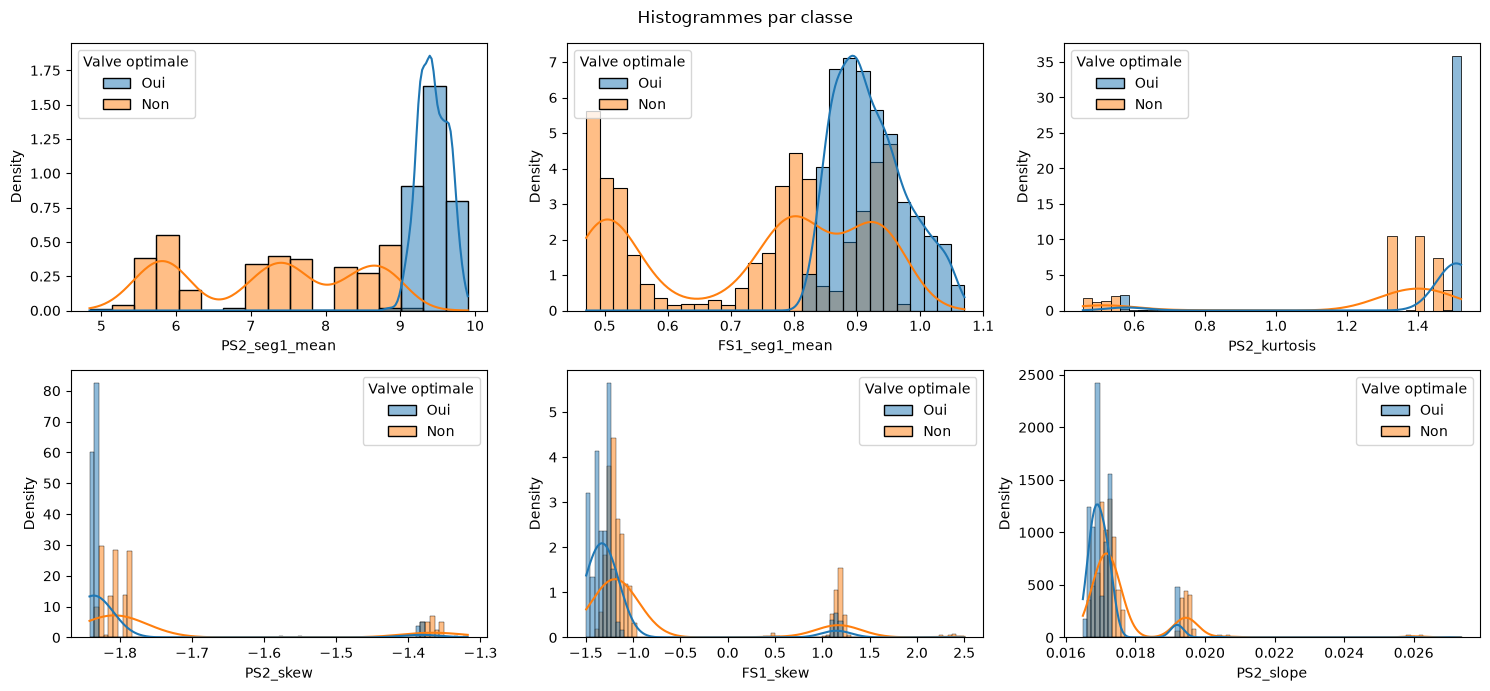

In [22]:
# Histogrammes des 6 variables les plus corrélées à la cible
top6 = corr_cible.index[:6].tolist()
donnees = X_dev[top6].copy()
donnees['Valve optimale'] = y_dev.map({0: 'Non', 1: 'Oui'})

fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, col in zip(axes.ravel(), top6):
    sns.histplot(data=donnees, x=col, hue='Valve optimale', kde=True, stat='density', common_norm=False, ax=ax)
fig.suptitle('Histogrammes par classe')
plt.tight_layout()
plt.show()

In [23]:
# 1.7 (suite) Vérification bis : qui sont les cycles du groupe isolé, et PS2_seg1_mean dépend-elle du Cooler ? (analyse uniquement)
grp = X_dev['PS2_skew'] > -1.6          # second groupe visible sur l'histogramme de PS2_skew
print('Part de cycles du groupe isolé : %.1f %%' % (grp.mean() * 100))
for col in ['Cooler', 'Pump_leakage', 'Accumulator']:
    print(f'\nPart du groupe isolé (%) selon {col} :')
    print((grp.groupby(profile_dev[col]).mean() * 100).round(1).to_string())

print('\nMédiane de PS2_seg1_mean selon (Valve en lignes, Cooler en colonnes) :')
print(X_dev['PS2_seg1_mean'].groupby([profile_dev['Valve'], profile_dev['Cooler']]).median().unstack().round(2))

Part de cycles du groupe isolé : 12.0 %

Part du groupe isolé (%) selon Cooler :
Cooler
3      32.8
20      0.0
100     0.0

Part du groupe isolé (%) selon Pump_leakage :
Pump_leakage
0     1.3
1    24.5
2    26.6

Part du groupe isolé (%) selon Accumulator :
Accumulator
90     11.1
100    27.1
115    17.8
130     0.7

Médiane de PS2_seg1_mean selon (Valve en lignes, Cooler en colonnes) :
Cooler   3     20    100
Valve                   
73      5.58  5.87  6.02
80      7.10  7.45  7.61
90      8.34  8.73  8.89
100     9.31  9.42  9.66


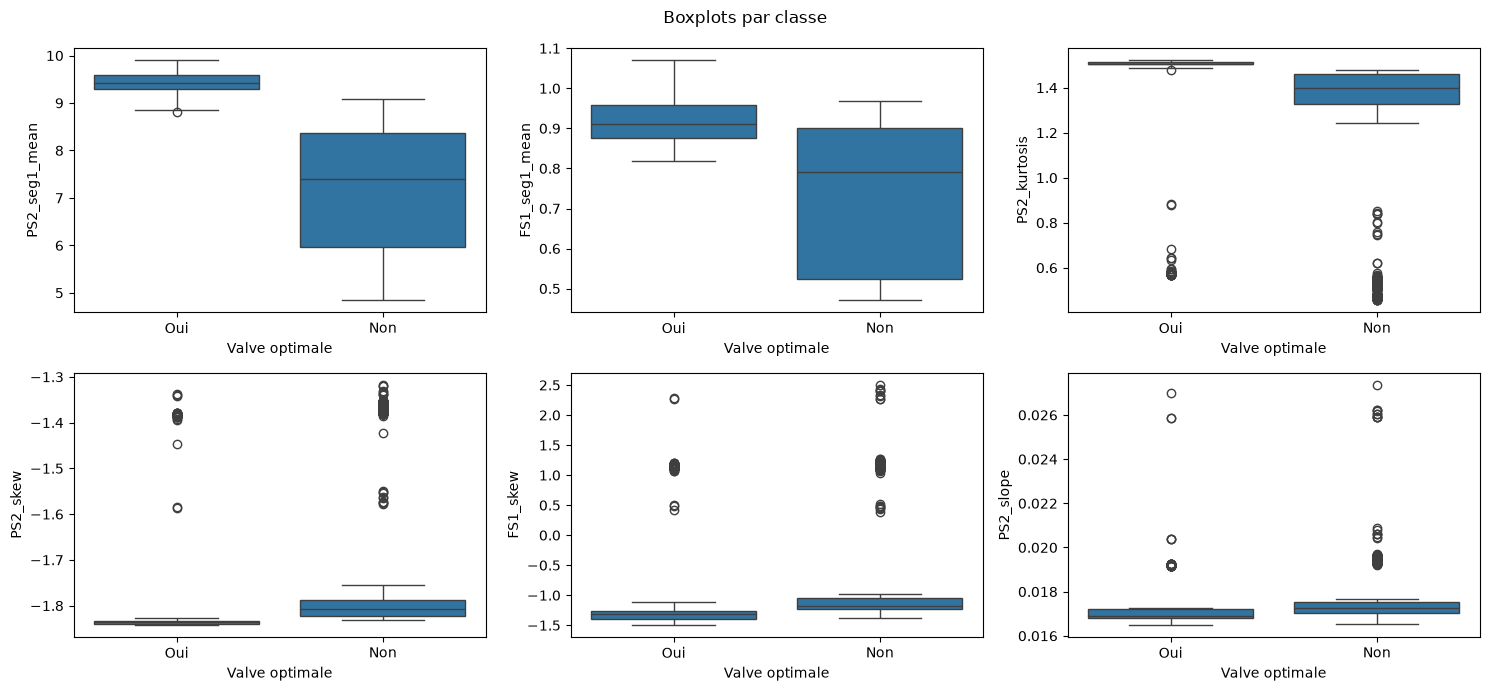

In [24]:
# Boxplots des 6 variables les plus corrélées à la cible
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, col in zip(axes.ravel(), top6):
    sns.boxplot(data=donnees, x='Valve optimale', y=col, ax=ax)
fig.suptitle('Boxplots par classe')
plt.tight_layout()
plt.show()

#### 1.8. Utilisation de méthodes de sélection de variables (Features selection). 

In [25]:
# Sélection de variables : filtre de colinéarité et scores de pertinence
from sklearn.feature_selection import f_classif, mutual_info_classif
from sklearn.ensemble import RandomForestClassifier

SEUIL_CORR = 0.95
SEUIL_COOLER = 10
K_FEATURES = 15

# a) Constantes, variables dominées par le Cooler, puis filtre de colinéarité (priorité aux plus corrélées à la cible)
m = (profile_dev['Cooler'] != 3).to_numpy()      # corrélations de référence hors Cooler = 3 % (analyse uniquement)
constantes = sorted(set(X_dev.columns[X_dev.nunique() <= 1]) | set(X_dev.columns[X_dev[m].nunique() <= 1]))
candidates = [c for c in X_dev.columns if c not in constantes]

F_valve, _ = f_classif(X_dev[candidates], y_dev)
F_cooler, _ = f_classif(X_dev[candidates], profile_dev['Cooler'])
ratio = pd.Series(F_cooler / F_valve, index=candidates)
dominees_cooler = ratio[ratio > SEUIL_COOLER].index.tolist()

corr_ref = X_dev[m].corr()
gardees = []
for feat in corr_cible.index:
    if feat in constantes or feat in dominees_cooler:
        continue
    if all(abs(corr_ref.loc[feat, g]) <= SEUIL_CORR for g in gardees):
        gardees.append(feat)

print(f'Variables de départ : {X_dev.shape[1]} | constantes : {len(constantes)} | dominées par le Cooler : {len(dominees_cooler)} | après filtre de colinéarité : {len(gardees)}')
print('Constantes :', constantes)
print('Dominées par le Cooler :', dominees_cooler)

# b) Trois critères de pertinence
Xs = X_dev[gardees]
f_scores, _ = f_classif(Xs, y_dev)
mi_scores = mutual_info_classif(Xs, y_dev, random_state=RANDOM_STATE)
rf = RandomForestClassifier(n_estimators=300, class_weight='balanced',
                            random_state=RANDOM_STATE, n_jobs=-1).fit(Xs, y_dev)

scores = pd.DataFrame({'ANOVA_F': f_scores, 'Info_mutuelle': mi_scores,
                       'RF_importance': rf.feature_importances_}, index=gardees)

# c) Agrégation par rang moyen (rang 1 = meilleure variable)
scores['Rang_moyen'] = scores.rank(ascending=False).mean(axis=1)
scores = scores.sort_values('Rang_moyen')
print(scores.round(4).head(K_FEATURES + 5))

Variables de départ : 38 | constantes : 2 | dominées par le Cooler : 7 | après filtre de colinéarité : 12
Constantes : ['FS1_min', 'PS2_min']
Dominées par le Cooler : ['PS2_max', 'PS2_range', 'PS2_q25', 'PS2_seg2_mean', 'PS2_seg6_mean', 'FS1_max', 'FS1_range']
                 ANOVA_F  Info_mutuelle  RF_importance  Rang_moyen
PS2_seg1_mean  3557.6588         0.6724         0.5487      1.0000
FS1_seg1_mean  1064.9580         0.3683         0.1580      2.0000
FS1_skew        143.2825         0.2723         0.0961      3.6667
PS2_slope       137.2580         0.3169         0.0528      3.6667
FS1_rms         120.5447         0.2016         0.0433      5.6667
FS1_std          70.6805         0.1802         0.0251      7.0000
FS1_seg2_mean    58.8154         0.2895         0.0280      7.0000
FS1_slope        68.6553         0.1202         0.0159      8.0000
PS2_seg5_mean    63.2010         0.2138         0.0107      8.6667
PS2_iqr          66.2373         0.0843         0.0061     10.3333
FS

In [26]:
# 1.8 (contrôle) PS2_kurtosis est-elle redondante avec les variables de début de cycle, hors Cooler = 3 % ?
print(corr_ref.loc['PS2_kurtosis', ['PS2_seg1_mean', 'FS1_seg1_mean']].round(3))

PS2_seg1_mean    0.997
FS1_seg1_mean    0.908
Name: PS2_kurtosis, dtype: float64


12 variables retenues :
['PS2_seg1_mean', 'FS1_seg1_mean', 'FS1_skew', 'PS2_slope', 'FS1_rms', 'FS1_std', 'FS1_seg2_mean', 'FS1_slope', 'PS2_seg5_mean', 'PS2_iqr', 'FS1_iqr', 'FS1_kurtosis']


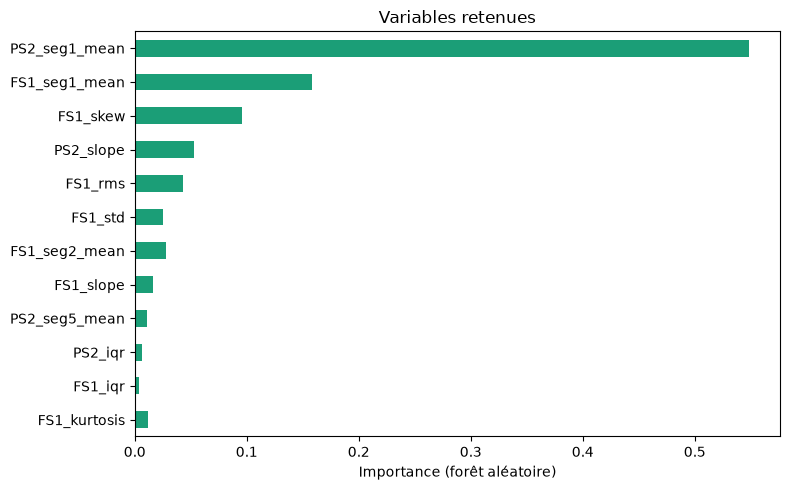

X_dev_sel : (2000, 12) | X_test_sel : (205, 12)


In [27]:
# Variables retenues et jeux de données prêts pour l'étape 2
selected_features = scores.index[:K_FEATURES].tolist()
print(f'{len(selected_features)} variables retenues :')
print(selected_features)

plt.figure(figsize=(8, 5))
scores.loc[selected_features, 'RF_importance'][::-1].plot.barh(color='#1b9e77')
plt.xlabel('Importance (forêt aléatoire)')
plt.title('Variables retenues')
plt.tight_layout()
plt.show()

# Mêmes colonnes pour le test final (aucune statistique du test n'est utilisée)
X_dev_sel, X_test_sel = X_dev[selected_features], X_test[selected_features]
print('X_dev_sel :', X_dev_sel.shape, '| X_test_sel :', X_test_sel.shape)

In [47]:
print(X_dev_sel.columns)

Index(['PS2_seg1_mean', 'FS1_seg1_mean', 'FS1_skew', 'PS2_slope', 'FS1_rms',
       'FS1_std', 'FS1_seg2_mean', 'FS1_slope', 'PS2_seg5_mean', 'PS2_iqr',
       'FS1_iqr', 'FS1_kurtosis'],
      dtype='str')


NameError: name 'X_dev_complet' is not defined

## 2. Modélisation et évaluation  

In [28]:
# A GARDER

# Préparation : jeux d'entraînement / validation et fonction d'évaluation
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

X_tr, X_val, y_tr, y_val = train_test_split(X_dev_sel, y_dev, test_size=0.2, stratify=y_dev,
                                            shuffle=True, random_state=RANDOM_STATE)
print('Entraînement :', X_tr.shape, '| Validation :', X_val.shape)
print('Part de valves optimales : entraînement = %.3f | validation = %.3f' % (y_tr.mean(), y_val.mean()))

modeles, resultats = {}, {}      # modèles entraînés et métriques de validation

def entrainer_et_evaluer(nom, modele, rapport=True):
    """Entraîne le modèle sur l'entraînement, l'évalue sur la validation et mémorise les résultats."""
    modele.fit(X_tr, y_tr)
    y_pred = modele.predict(X_val)
    modeles[nom] = modele
    resultats[nom] = {'Accuracy': accuracy_score(y_val, y_pred),
                      'Précision': precision_score(y_val, y_pred),
                      'Rappel': recall_score(y_val, y_pred),
                      'F1': f1_score(y_val, y_pred),
                      'Accuracy (train)': modele.score(X_tr, y_tr)}
    if rapport:
        print(f'************* {nom} *************')
        print(confusion_matrix(y_val, y_pred))
        print(classification_report(y_val, y_pred, target_names=['Non optimale', 'Optimale']))
    return modele

Entraînement : (1600, 12) | Validation : (400, 12)
Part de valves optimales : entraînement = 0.526 | validation = 0.525


In [29]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import RocCurveDisplay

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Nous utilisons RANDOM_STATE pour la reproductibilité (assurez-vous de l'avoir défini, ex: RANDOM_STATE = 42)
RANDOM_STATE = 42

# Définition des modèles réclamés par le sujet
# L'utilisation de make_pipeline garantit que la normalisation est ajustée sur X_tr uniquement, évitant la fuite de données.
modeles_a_tester = {
    'Régression Logistique': make_pipeline(StandardScaler(), LogisticRegression(random_state=RANDOM_STATE)),
    'k-NN': make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
    'Arbre de Décision': DecisionTreeClassifier(random_state=RANDOM_STATE),
    'Naive Bayes': GaussianNB(), # Pas de normalisation requise
    'SVM': make_pipeline(StandardScaler(), SVC(probability=True, random_state=RANDOM_STATE)),
    'Random Forest (Ensemble)': RandomForestClassifier(random_state=RANDOM_STATE),
    'Gradient Boosting (Ensemble)': GradientBoostingClassifier(random_state=RANDOM_STATE)
}

In [30]:
# Entraînement et évaluation en boucle
print("Entraînement des modèles en cours...\n")
for nom, modele in modeles_a_tester.items():
    # Appel de votre fonction existante
    entrainer_et_evaluer(nom, modele, rapport=False) 
    print(f"✅ {nom} entraîné.")

Entraînement des modèles en cours...

✅ Régression Logistique entraîné.
✅ k-NN entraîné.
✅ Arbre de Décision entraîné.
✅ Naive Bayes entraîné.
✅ SVM entraîné.
✅ Random Forest (Ensemble) entraîné.
✅ Gradient Boosting (Ensemble) entraîné.


In [31]:
# Création d'un DataFrame à partir de votre dictionnaire 'resultats'
df_resultats = pd.DataFrame(resultats).T

# Tri par F1-score décroissant, car c'est la métrique la plus équilibrée pour ce type de problème
df_resultats = df_resultats.sort_values(by='F1', ascending=False)

print("Comparaison des performances des modèles sur le jeu de validation :")
display(df_resultats) # Utilisez print(df_resultats) si vous n'êtes pas sur un notebook

Comparaison des performances des modèles sur le jeu de validation :


,Accuracy,Précision,Rappel,F1,Accuracy (train)
Régression Logistique,1.0000,1.000000,1.000000,1.000000,1.000000
Random Forest (Ensemble),1.0000,1.000000,1.000000,1.000000,1.000000
Arbre de Décision,0.9975,1.000000,0.995238,0.997613,1.000000
Gradient Boosting (Ensemble),0.9975,1.000000,0.995238,0.997613,1.000000
k-NN,0.9925,1.000000,0.985714,0.992806,0.997500
SVM,0.9925,1.000000,0.985714,0.992806,0.997500
Naive Bayes,0.8750,0.836134,0.947619,0.888393,0.879375


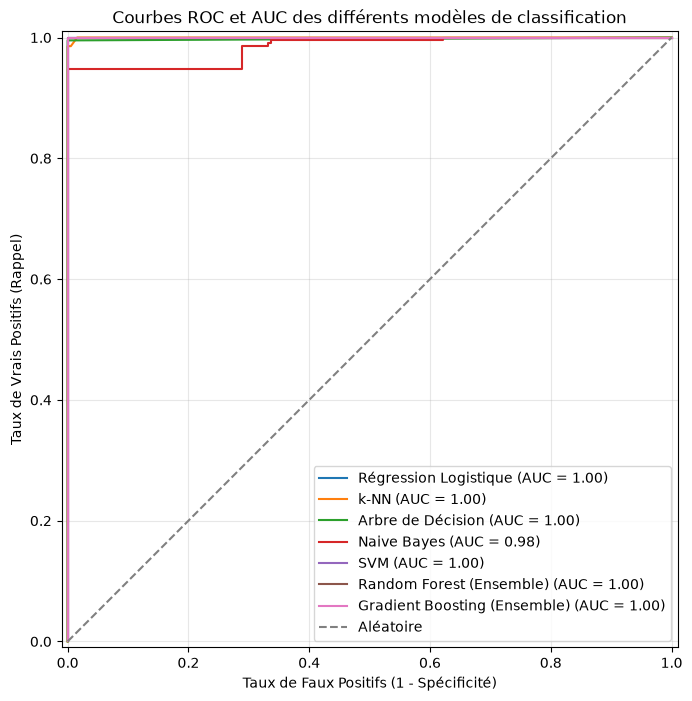

In [32]:
fig, ax = plt.subplots(figsize=(10, 8))

# Parcours des modèles entraînés pour tracer leur courbe ROC respective
for nom, modele in modeles.items():
    RocCurveDisplay.from_estimator(modele, X_val, y_val, ax=ax, name=nom)

# Ligne de base (classifieur aléatoire)
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Aléatoire')

plt.title('Courbes ROC et AUC des différents modèles de classification')
plt.xlabel('Taux de Faux Positifs (1 - Spécificité)')
plt.ylabel('Taux de Vrais Positifs (Rappel)')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.show()

#### 2.1. Régression logistique.

In [33]:
# 2.1 Régression logistique
from sklearn.linear_model import LogisticRegression

log_reg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
entrainer_et_evaluer('Régression logistique', log_reg)

************* Régression logistique *************
[[190   0]
 [  0 210]]
              precision    recall  f1-score   support

Non optimale       1.00      1.00      1.00       190
    Optimale       1.00      1.00      1.00       210

    accuracy                           1.00       400
   macro avg       1.00      1.00      1.00       400
weighted avg       1.00      1.00      1.00       400



,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](12,)","['PS2_seg1_mean','FS1_seg1_mean','FS1_skew',...,'PS2_iqr','FS1_iqr', 'FS1_kurtosis']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,12
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [34]:
# Coefficients du modèle (variables standardisées : comparables entre eux)
coef = pd.Series(log_reg[-1].coef_[0], index=X_tr.columns).sort_values(key=abs, ascending=False)
print(coef.round(3))
print('Intercept :', round(float(log_reg[-1].intercept_[0]), 3))

PS2_seg1_mean    9.996
PS2_iqr          2.367
PS2_slope       -2.302
FS1_slope       -2.060
FS1_rms         -1.638
FS1_std         -1.429
FS1_seg2_mean    1.351
PS2_seg5_mean   -1.080
FS1_kurtosis    -0.753
FS1_seg1_mean    0.585
FS1_skew        -0.496
FS1_iqr          0.417
dtype: float64
Intercept : -4.262


#### 2.2. k-NN.

In [35]:
# variables standardisées : méthode basée sur des distances)
from sklearn.neighbors import KNeighborsClassifier

for k in [1, 3, 5, 7]:
    knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    entrainer_et_evaluer(f'k-NN (k={k})', knn, rapport=(k == 5))     # rapport détaillé pour k = 5

print(pd.DataFrame(resultats).T.loc[[f'k-NN (k={k})' for k in [1, 3, 5, 7]]].round(3))

************* k-NN (k=5) *************
[[190   0]
 [  3 207]]
              precision    recall  f1-score   support

Non optimale       0.98      1.00      0.99       190
    Optimale       1.00      0.99      0.99       210

    accuracy                           0.99       400
   macro avg       0.99      0.99      0.99       400
weighted avg       0.99      0.99      0.99       400

            Accuracy  Précision  Rappel     F1  Accuracy (train)
k-NN (k=1)     0.998        1.0   0.995  0.998             1.000
k-NN (k=3)     0.992        1.0   0.986  0.993             0.999
k-NN (k=5)     0.992        1.0   0.986  0.993             0.998
k-NN (k=7)     0.992        1.0   0.986  0.993             0.996


#### 2.3. Arbre de décision.

In [36]:
from sklearn.tree import DecisionTreeClassifier, plot_tree

arbre = DecisionTreeClassifier(criterion='entropy', random_state=RANDOM_STATE)
entrainer_et_evaluer('Arbre de décision (profondeur libre)', arbre)
print(f'Profondeur : {arbre.get_depth()} | feuilles : {arbre.get_n_leaves()}')

arbre5 = DecisionTreeClassifier(criterion='entropy', max_depth=5, random_state=RANDOM_STATE)
entrainer_et_evaluer('Arbre de décision (max_depth=5)', arbre5, rapport=False)

************* Arbre de décision (profondeur libre) *************
[[190   0]
 [  0 210]]
              precision    recall  f1-score   support

Non optimale       1.00      1.00      1.00       190
    Optimale       1.00      1.00      1.00       210

    accuracy                           1.00       400
   macro avg       1.00      1.00      1.00       400
weighted avg       1.00      1.00      1.00       400

Profondeur : 4 | feuilles : 8


,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'entropy'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples

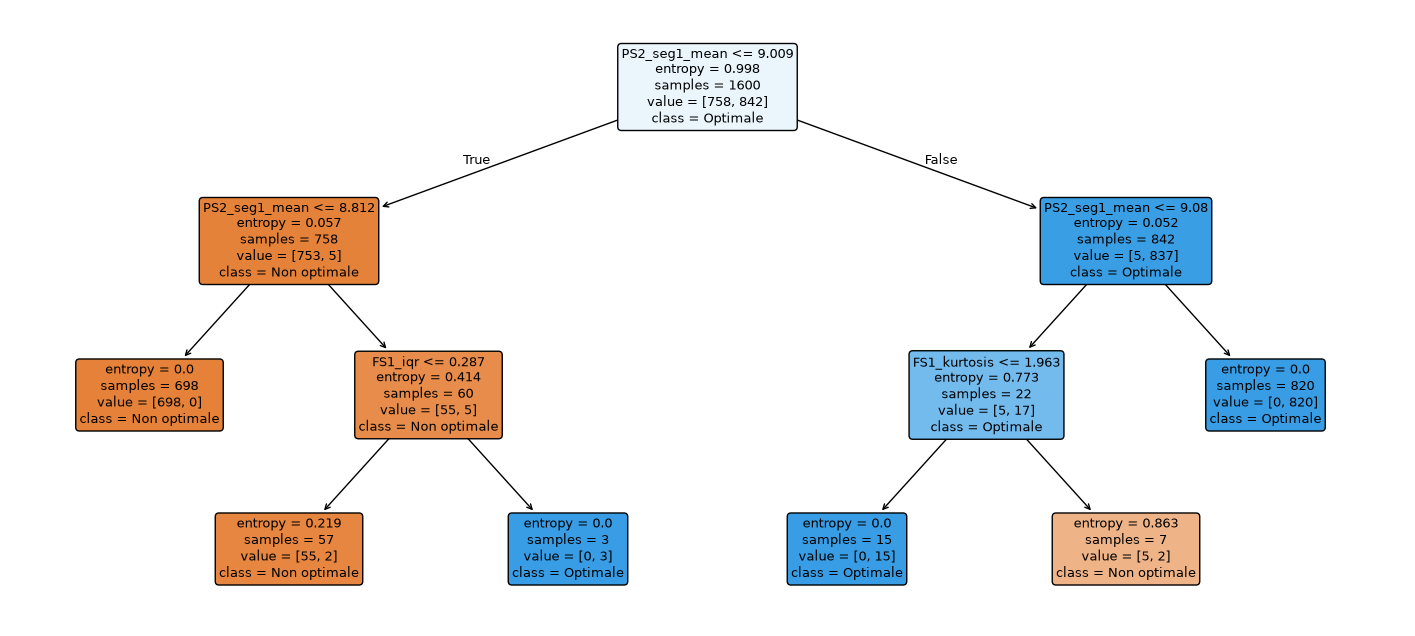

In [37]:
# Visualisation d'un arbre simple (profondeur 3) pour l'interprétation
arbre3 = DecisionTreeClassifier(criterion='entropy', max_depth=3, random_state=RANDOM_STATE).fit(X_tr, y_tr)

plt.figure(figsize=(18, 8))
plot_tree(arbre3, feature_names=list(X_tr.columns), class_names=['Non optimale', 'Optimale'],
          filled=True, rounded=True, fontsize=9)
plt.show()

#### 2.4. Naive Bayes.

In [38]:
# Naive Bayes gaussien (standardisation : le lissage de variance de scikit-learn dépend de l'échelle des variables)
from sklearn.naive_bayes import GaussianNB

entrainer_et_evaluer('Naive Bayes gaussien', make_pipeline(StandardScaler(), GaussianNB()))

************* Naive Bayes gaussien *************
[[151  39]
 [ 11 199]]
              precision    recall  f1-score   support

Non optimale       0.93      0.79      0.86       190
    Optimale       0.84      0.95      0.89       210

    accuracy                           0.88       400
   macro avg       0.88      0.87      0.87       400
weighted avg       0.88      0.88      0.87       400



,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('gaussiannb', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](12,)","['PS2_seg1_mean','FS1_seg1_mean','FS1_skew',...,'PS2_iqr','FS1_iqr', 'FS1_kurtosis']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,12
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


#### 2.5. SVM.

In [39]:
# SVM (variables standardisées)
from sklearn.svm import SVC

entrainer_et_evaluer('SVM linéaire', make_pipeline(StandardScaler(), SVC(kernel='linear')))
entrainer_et_evaluer('SVM RBF', make_pipeline(StandardScaler(), SVC(kernel='rbf')))

************* SVM linéaire *************
[[190   0]
 [  0 210]]
              precision    recall  f1-score   support

Non optimale       1.00      1.00      1.00       190
    Optimale       1.00      1.00      1.00       210

    accuracy                           1.00       400
   macro avg       1.00      1.00      1.00       400
weighted avg       1.00      1.00      1.00       400

************* SVM RBF *************
[[190   0]
 [  3 207]]
              precision    recall  f1-score   support

Non optimale       0.98      1.00      0.99       190
    Optimale       1.00      0.99      0.99       210

    accuracy                           0.99       400
   macro avg       0.99      0.99      0.99       400
weighted avg       0.99      0.99      0.99       400



,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('svc', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](12,)","['PS2_seg1_mean','FS1_seg1_mean','FS1_skew',...,'PS2_iqr','FS1_iqr', 'FS1_kurtosis']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,12
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


#### 2.6. Ensemble learning.

In [40]:
# Bagging (forêt aléatoire), boosting (gradient boosting) et vote
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, VotingClassifier

foret = RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1)
entrainer_et_evaluer('Forêt aléatoire (bagging)', foret)

gboost = GradientBoostingClassifier(random_state=RANDOM_STATE)
entrainer_et_evaluer('Gradient Boosting (boosting)', gboost)

************* Forêt aléatoire (bagging) *************
[[190   0]
 [  0 210]]
              precision    recall  f1-score   support

Non optimale       1.00      1.00      1.00       190
    Optimale       1.00      1.00      1.00       210

    accuracy                           1.00       400
   macro avg       1.00      1.00      1.00       400
weighted avg       1.00      1.00      1.00       400

************* Gradient Boosting (boosting) *************
[[190   0]
 [  1 209]]
              precision    recall  f1-score   support

Non optimale       0.99      1.00      1.00       190
    Optimale       1.00      1.00      1.00       210

    accuracy                           1.00       400
   macro avg       1.00      1.00      1.00       400
weighted avg       1.00      1.00      1.00       400



,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to each Tree estimator at eachboosting iteration.In addition, it controls the random permutation of the features ateach split (see Notes for more details).It also controls the random splitting of the training data to obtain avalidation set if `n_iter_no_change` is not None.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'log_loss', 'exponential'}, default='log_loss'The loss function to be optimized. 'log_loss' refers to binomial andmultinomial deviance, the same as used in logistic regression.It is a good choice for classification with probabilistic outputs.For loss 'exponential', gradient boosting recovers the AdaBoost algorithm.",'log_loss'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.For an example of the effects of this parameter and its interaction with``subsample``, see:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_regularization.py`.",0.1
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",100
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'This parameter has no effect... versionadded:: 0.18.. deprecated:: 1.9 `criterion` is deprecated and will be removed in 1.11.",'deprecated'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",3
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf)`.The weighted impurity decrease equation is the following:: N_t / N * (im

In [41]:
# 2.6 (suite) Vote pondéré par les probabilités : combine un modèle linéaire, un SVM non linéaire et une forêt
vote = VotingClassifier(
    estimators=[
        ('lr', make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))),
        ('svm', make_pipeline(StandardScaler(), SVC(kernel='rbf', probability=True, random_state=RANDOM_STATE))),
        ('rf', RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1)),
    ],
    voting='soft')
entrainer_et_evaluer('Vote (LR + SVM RBF + RF)', vote)

************* Vote (LR + SVM RBF + RF) *************
[[190   0]
 [  0 210]]
              precision    recall  f1-score   support

Non optimale       1.00      1.00      1.00       190
    Optimale       1.00      1.00      1.00       210

    accuracy                           1.00       400
   macro avg       1.00      1.00      1.00       400
weighted avg       1.00      1.00      1.00       400



,"estimators estimators: list of (str, estimator) tuplesInvoking the ``fit`` method on the ``VotingClassifier`` will fit clonesof those original estimators that will be stored in the class attribute``self.estimators_``. An estimator can be set to ``'drop'`` using:meth:`set_params`... versionchanged:: 0.21 ``'drop'`` is accepted. Using None was deprecated in 0.22 and support was removed in 0.24.","[('lr', ...), ('svm', ...), ...]"
,"voting voting: {'hard', 'soft'}, default='hard'If 'hard', uses predicted class labels for majority rule voting.Else if 'soft', predicts the class label based on the argmax ofthe sums of the predicted probabilities, which is recommended foran ensemble of well-calibrated classifiers.",'soft'
,"weights weights: array-like of shape (n_classifiers,), default=NoneSequence of weights (`float` or `int`) to weight the occurrences ofpredicted class labels (`hard` voting) or class probabilitiesbefore averaging (`soft` voting). Uses uniform weights if `None`.",None
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for ``fit``.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionadded:: 0.18",None
,"flatten_transform flatten_transform: bool, default=TrueAffects shape of transform output only when voting='soft'If voting='soft' and flatten_transform=True, transform method returnsmatrix with shape (n_samples, n_classifiers * n_classes). Ifflatten_transform=False, it returns(n_classifiers, n_samples, n_classes).",True
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting will be printed as itis completed... versionadded:: 0.23",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels.","ndarray[int64](2,)","[0,1]"
"estimators_ estimators_: list of classifiersThe collection of fitted sub-estimators as defined in ``estimators``that are not 'drop'. Note that sub-estimators are always fitted oninteger-encoded labels (see ``le_`` attribute). When ``y`` containsnon-integer class labels (e.g. strings), use ``le_.inverse_transform``to map predictions back to the original label space.",list,"[Pipeline(step...m_state=42))]), Pipeline(step...m_state=42))]), RandomForestC...ndom_state=42)]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimators expose such an attribute when fit... versionadded:: 1.0","ndarray[object](12,)","['PS2_seg1_mean','FS1_seg1_mean','FS1_skew',...,'PS2_iqr','FS1_iqr', 'FS1_kurtosis']"
le_ le_: :class:`~sklearn.preprocessing.LabelEncoder`Transformer used to encode the labels during fit and decode duringprediction. Sub-estimators in ``estimators_`` are fitted on theinteger-encoded labels produced by this encoder.,LabelEncoder,LabelEncoder()


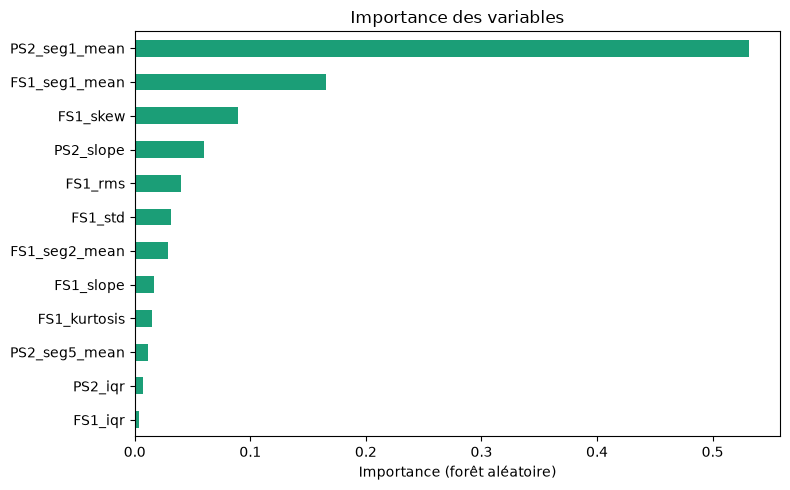

In [42]:
# 2.6 (suite) Importance des variables selon la forêt aléatoire
imp = pd.Series(foret.feature_importances_, index=X_tr.columns).sort_values()

plt.figure(figsize=(8, 5))
imp.plot.barh(color='#1b9e77')
plt.xlabel('Importance (forêt aléatoire)')
plt.title('Importance des variables')
plt.tight_layout()
plt.show()

#### 2.7. Justification du choix des modèles.

In [43]:
# 2.7 Tableau récapitulatif des modèles (jeu de validation)
recap = pd.DataFrame(resultats).T.sort_values('F1', ascending=False)
recap['Écart train - validation'] = recap['Accuracy (train)'] - recap['Accuracy']
recap.round(3)

,Accuracy,Précision,Rappel,F1,Accuracy (train),Écart train - validation
Régression Logistique,1.000,1.000,1.000,1.000,1.000,0.000
Arbre de décision (max_depth=5),1.000,1.000,1.000,1.000,1.000,0.000
Régression logistique,1.000,1.000,1.000,1.000,1.000,0.000
Random Forest (Ensemble),1.000,1.000,1.000,1.000,1.000,0.000
Forêt aléatoire (bagging),1.000,1.000,1.000,1.000,1.000,0.000
SVM linéaire,1.000,1.000,1.000,1.000,1.000,0.000
Arbre de décision (profondeur libre),1.000,1.000,1.000,1.000,1.000,0.000
Vote (LR + SVM RBF + RF),1.000,1.000,1.000,1.000,1.000,0.000
k-NN (k=1),0.998,1.000,0.995,0.998,1.000,0.002
Gradient Boosting (boosting),0.998,1.000,0.995,0.998,1.000,0.002


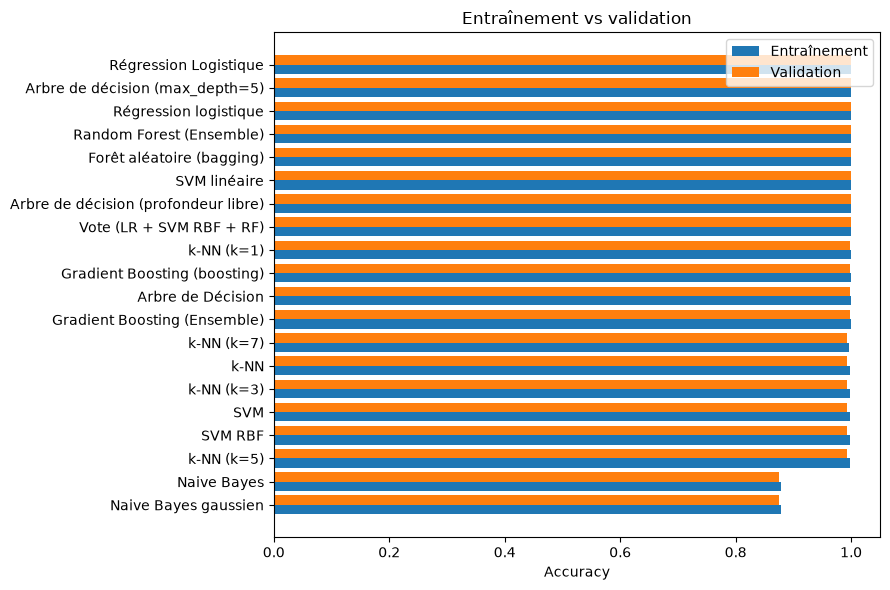

In [44]:
# 2.7 (suite) Précision d'entraînement vs validation : repérer le sur-apprentissage
ordre = recap.index[::-1]
pos = np.arange(len(ordre))

plt.figure(figsize=(9, 6))
plt.barh(pos - 0.2, recap.loc[ordre, 'Accuracy (train)'], height=0.4, label='Entraînement')
plt.barh(pos + 0.2, recap.loc[ordre, 'Accuracy'], height=0.4, label='Validation')
plt.yticks(pos, ordre)
plt.xlabel('Accuracy')
plt.title('Entraînement vs validation')
plt.legend()
plt.tight_layout()
plt.show()

In [45]:
# 2.7 (suite) Caractéristiques des données qui guident le choix des modèles
n = X_dev_sel.shape[1]
corr_sel = X_dev_sel.corr().abs().where(~np.eye(n, dtype=bool), 0)

resume = pd.DataFrame({'Asymétrie': X_dev_sel.skew(),
                       'Kurtosis': X_dev_sel.kurt(),
                       'Min': X_dev_sel.min(),
                       'Max': X_dev_sel.max(),
                       '|r| max avec une autre variable': corr_sel.max()})
print(resume.round(2))

etendues = X_dev_sel.max() - X_dev_sel.min()
print(f'\nRapport entre la plus grande et la plus petite étendue : {etendues.max() / etendues.min():.1f}')

               Asymétrie  Kurtosis     Min     Max  \
PS2_seg1_mean      -0.94     -0.54    4.84    9.90   
FS1_seg1_mean      -1.21      0.32    0.47    1.07   
FS1_skew            2.35      3.92   -1.50    2.50   
PS2_slope           4.46     29.27    0.02    0.03   
FS1_rms            -2.36      4.18    3.35    7.38   
FS1_std             2.22      3.61    2.66    3.74   
FS1_seg2_mean      -1.49      1.61    6.87    8.25   
FS1_slope          -4.07     23.03   -0.01    0.01   
PS2_seg5_mean       2.26      3.29  124.46  165.50   
PS2_iqr             2.34      3.48    9.12   51.80   
FS1_iqr             2.42      3.88    0.05    6.66   
FS1_kurtosis        3.46     38.19   -0.35    7.66   

               |r| max avec une autre variable  
PS2_seg1_mean                             0.90  
FS1_seg1_mean                             0.90  
FS1_skew                                  0.99  
PS2_slope                                 0.96  
FS1_rms                                   0.99  
FS1

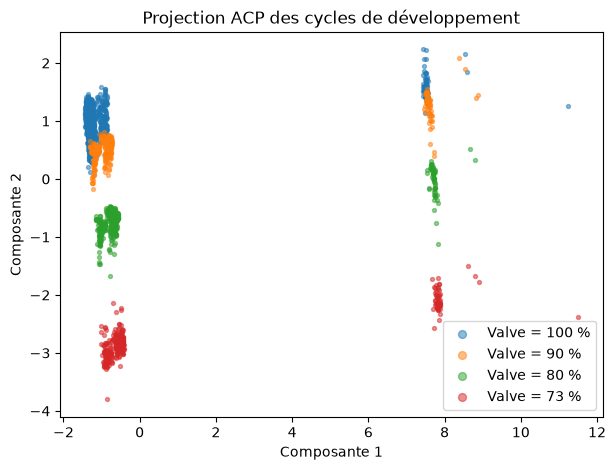

In [46]:
# 2.7 (suite) Les cycles « non optimaux » regroupent trois états de valve : projection en 2 dimensions (ACP)
from sklearn.decomposition import PCA

Z = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(StandardScaler().fit_transform(X_dev_sel))

plt.figure(figsize=(7, 5))
for val in sorted(profile_dev['Valve'].unique(), reverse=True):
    m = (profile_dev['Valve'] == val).to_numpy()
    plt.scatter(Z[m, 0], Z[m, 1], s=8, alpha=0.5, label=f'Valve = {val} %')
plt.xlabel('Composante 1')
plt.ylabel('Composante 2')
plt.title('Projection ACP des cycles de développement')
plt.legend(markerscale=2)
plt.show()